# Week 7 (extra): the same questions with pandas

In the Week 7 notes we answered two questions about the Giller nominees using plain Python: loops, dictionaries, and functions we wrote ourselves.

1. How Canadian are the nominees?
2. Are they concentrated in the big cities?

This notebook answers the same questions with **pandas**, a Python library made for working with tables. You don't need to learn pandas for this course. The point is to see that the *thinking* is the same: we make the same cleaning decisions and get the same answers. Pandas just does the looping for us.

A few ideas to keep in mind:
- A pandas **DataFrame** is a whole table: rows and named columns, like a spreadsheet.
- One column of a DataFrame is a **Series**. Instead of writing a `for` loop over the values, we apply an operation to the whole column at once.
- String methods we know, like `.strip()` and `.split()`, work on a whole column through `.str`, as in `column.str.strip()`.

## 1. Loading the data

`pd.read_csv()` reads the whole CSV file into a DataFrame in one step. (`import pandas as pd` is a convention: everyone abbreviates pandas as `pd`.)

In [49]:
import pandas as pd

nominees = pd.read_csv("giller_nominees_clean.csv")

print(len(nominees), "nominated books")
nominees.head()

312 nominated books


,Year,Title,Author,Publisher,Publisher Location,Born,DOB,Residence,DOD,Bio,Novel
0,2013,Oct-70,"Louis Hamelin, translated by Wayne Grady",NaN,NaN,"Saint-Séverin-de-Proulxville, QC",09/06/1959,-,00/00/00,https://en.wikipedia.org/wiki/Louis_Hamelin,NaN
1,2024,The Cure for Drowning,Loghan Paylor,NaN,NaN,Ontario,-,"Abbotsford, BC",00/00/00,https://en.wikipedia.org/wiki/Loghan_Paylor,NaN
2,2014,The Ever After of Ashwin Rao,Padma Viswanathan,NaN,NaN,"Nelson, BC",20/02/1968,"Arkansas, USA",00/00/00,https://en.wikipedia.org/wiki/Padma_Viswanatha...,NaN
3,2018,Our Homesick Love Songs,Emma Hooper,NaN,NaN,Alberta,-,"Bath, England",00/00/00,https://en.wikipedia.org/wiki/Emma_Hooper ; ht...,NaN
4,1995,The Piano Man’s Daughter,Timothy Findley,NaN,NaN,"Toronto, ON",30/10/1930,"Brignoles, France",20/06/2002,https://en.wikipedia.org/wiki/Timothy_Findley,NaN


`.head()` shows the first five rows. Notice that empty cells show up as `NaN` ("not a number"), which is how pandas marks missing values.

Our rows are books, but we want to count **authors**. In the notes we built a dictionary keyed by author. In pandas, `.drop_duplicates()` keeps one row per author. (`keep="last"` matches what our dictionary did: when an author appeared again, their value was overwritten.)

In [50]:
authors = nominees.drop_duplicates("Author", keep="last")
authors = authors[["Author", "Born", "Residence"]].copy()   # keep only the columns we need

print(len(authors), "authors")
authors.head()

218 authors


,Author,Born,Residence
0,"Louis Hamelin, translated by Wayne Grady","Saint-Séverin-de-Proulxville, QC",-
1,Loghan Paylor,Ontario,"Abbotsford, BC"
2,Padma Viswanathan,"Nelson, BC","Arkansas, USA"
3,Emma Hooper,Alberta,"Bath, England"
5,Timothy Findley,"Toronto, ON","Brignoles, France"


## 2. Where were the nominees born?

### Getting the region

In the notes, `get_region()` did three things: strip stray commas, split on `","`, and take the last piece. We'll do the same three steps here, one at a time. Each step works on the **whole column** at once, so each line replaces a loop.

In [51]:
# Step 1: remove stray commas from the ends of each birthplace
born = authors["Born"].str.strip(",")

# Step 2: split each birthplace into a list of pieces
parts = born.str.split(",")

parts.head()

0    [Saint-Séverin-de-Proulxville,  QC]
1                              [Ontario]
2                          [Nelson,  BC]
3                              [Alberta]
5                         [Toronto,  ON]
Name: Born, dtype: object

Each value in `parts` is now a list, like `['Nelson', ' BC']`. 

`.str[-1]` takes the last item from **each** list, just like `parts[-1]` did for a single list in the notes. Then we strip the spaces.

Finally, we store the result as a **new column** of `authors`. Assigning to a column name that doesn't exist yet adds it, just like adding a new key to a dictionary.

In [52]:
# Step 3: take the last piece of each list
last_piece = parts.str[-1]

# Step 4: remove the spaces around it, and store it as a new column
authors["Born region"] = last_piece.str.strip()

authors.head()

,Author,Born,Residence,Born region
0,"Louis Hamelin, translated by Wayne Grady","Saint-Séverin-de-Proulxville, QC",-,QC
1,Loghan Paylor,Ontario,"Abbotsford, BC",Ontario
2,Padma Viswanathan,"Nelson, BC","Arkansas, USA",BC
3,Emma Hooper,Alberta,"Bath, England",Alberta
5,Timothy Findley,"Toronto, ON","Brignoles, France",ON


Now we can count the regions. `.value_counts()` replaces our counting loop: it counts how many times each value appears, from most to least common.

In [53]:
authors["Born region"].value_counts()

Born region
ON                     62
BC                     25
QC                     23
AB                     13
NL                     10
England                 9
USA                     8
MB                      8
SK                      7
NS                      5
-                       3
Lebanon                 2
Sri Lanka               2
West Germany            2
Hong Kong               2
South Africa            2
Israel                  2
Ireland                 2
Trinidad and Tobago     2
Nigeria                 2
NB                      2
British Columbia        1
Tibet                   1
Barbados                1
Saudi Arabia            1
Latvia                  1
NU                      1
Thailand                1
Venezuela               1
Canada                  1
MD                      1
Yugoslavia              1
China                   1
Kenya                   1
India                   1
Germany                 1
Serbia                  1
Egypt                   1


### Cleaning with our corrections dictionary

`.replace()` takes the same kind of dictionary we built in the notes: messy value → corrected value. Here are all of the corrections from the notes in one place, for birthplaces and residences.

In [54]:
corrections = {
    # Full province names: use the abbreviations found everywhere else
    "Ontario": "ON",
    "Alberta": "AB",
    "British Columbia": "BC",
    "New Brunswick": "NB",
    "Newfoundland": "NL",
    "Nova Scotia": "NS",
    "Quebec": "QC",
    "South-Eastern Ontario": "ON",
    # The United States, written different ways
    "MD": "USA",
    "IL": "USA",
    "TX": "USA",
    "US": "USA",
    "United States": "USA",
    # Leftovers from the "first place" rule (see section 3)
    "Galiano Island": "BC",
    "Toronto": "ON",
}

canadian_regions = ["AB", "BC", "MB", "NB", "NL", "NS", "NT", "NU", "ON", "PE", "QC", "SK", "YT", "Canada", "Treaty 6 Territory"]

### Born in Canada, or elsewhere?

`.isin(canadian_regions)` asks "is this value in the list?" of every row. It gives a column of `True`/`False` values. We drop the unknown birthplaces (`"-"`) first, using a **filter**: putting a column of `True`/`False` values inside square brackets keeps only the rows where it is `True`.

In [55]:
# Apply our corrections to the region column
authors["Born region"] = authors["Born region"].replace(corrections)

# Keep only the authors whose birthplace is known
known_born = authors[authors["Born region"] != "-"]

born_in_canada = known_born["Born region"].isin(canadian_regions)
born_in_canada.value_counts(normalize=True) * 100

Born region
True     74.418605
False    25.581395
Name: proportion, dtype: float64

`normalize=True` gives proportions instead of counts, and multiplying by 100 turns them into percentages. `True` means born in Canada: the same 74% we found in the notes.

## 3. Where do the nominees live now?

We apply the same "first place listed" rule as in the notes: split on `" and "` and keep the first piece. Then we follow the same recipe as for birthplaces. Because we'll use it more than once, we write it as a function that takes a whole column.

In [56]:
def get_regions(places):
    """ Return a Series with the cleaned region of each place in places
        (a Series), using the first place listed.
    """
    # Use the first place listed
    place_lists = places.str.split(" and ")
    first = place_lists.str[0]

    # The same steps we used for birthplaces in section 2
    first = first.str.strip(",")
    parts = first.str.split(",")
    last_piece = parts.str[-1]
    regions = last_piece.str.strip()

    return regions.replace(corrections)


home_region = get_regions(authors["Residence"])
home_region.value_counts()

Residence
ON                    88
BC                    39
QC                    24
USA                   17
England                8
AB                     7
NL                     7
SK                     5
MB                     4
NS                     4
NB                     3
France                 3
Australia              1
Ireland                1
Egypt                  1
Nigeria                1
NU                     1
Scotland               1
Treaty 6 Territory     1
United Kingdom         1
-                      1
Name: count, dtype: int64

In [57]:
home_region = home_region[home_region != "-"]

lives_in_canada = home_region.isin(canadian_regions)
lives_in_canada.value_counts(normalize=True) * 100

Residence
True     84.331797
False    15.668203
Name: proportion, dtype: float64

## 4. How Canadian? Putting birth and residence together

In the notes we needed a loop with four counters and `if`/`elif` to sort authors into four groups. Pandas has a function for exactly this kind of two-way table: `pd.crosstab()`. It counts how many rows fall into each combination of two columns.

First we put the information we need side by side in one DataFrame. For this table we also drop the authors with an unknown birthplace or residence, keeping the rest in `known`.

In [58]:
places = pd.DataFrame({
    "Author": authors["Author"],
    "born": get_regions(authors["Born"]),
    "home": get_regions(authors["Residence"]),
})
places["Born in Canada"] = places["born"].isin(canadian_regions)
places["Lives in Canada"] = places["home"].isin(canadian_regions)

known = places[(places["born"] != "-") & (places["home"] != "-")]
pd.crosstab(known["Born in Canada"], known["Lives in Canada"])

Lives in Canada,False,True
Born in Canada,,
False,9,46
True,25,134


(In pandas, `&` plays the role of `and` when combining filters, and each condition needs its own parentheses.)

The same table as percentages of all authors. `.round(0)` rounds to whole numbers:

In [59]:
(pd.crosstab(known["Born in Canada"], known["Lives in Canada"], normalize="all") * 100).round(0)

Lives in Canada,False,True
Born in Canada,,
False,4.0,21.0
True,12.0,63.0


Who was neither born in Canada nor lives there? `~` means "not".

In [60]:
neither = known[~known["Born in Canada"] & ~known["Lives in Canada"]]
neither["Author"].tolist()

['Noor Naga',
 'Claire Messud',
 'Cheluchi Onyemeluke-Onubi',
 'Tom Rachman',
 'Steve Weiner',
 'Clark Blaise',
 'Omar El Akkad',
 'Paulette Jiles',
 'Dan Vyleta']

## 5. Are the nominees concentrated in the big cities?

As in the notes, we keep the city **and** the region together (to tell `London, ON` from `London, England`), and use the same `metro_areas` dictionary for suburbs.

In [61]:
big_cities = ["Toronto, ON", "Montreal, QC", "Vancouver, BC"]

metro_areas = {
    # Suburbs inside the Toronto census metropolitan area
    "Scarborough, ON": "Toronto, ON",
    "Willowdale, ON": "Toronto, ON",
    "Mississauga, ON": "Toronto, ON",
    "Brampton, ON": "Toronto, ON",
    "Markham, ON": "Toronto, ON",
    "Newmarket, ON": "Toronto, ON",
    "Richmond Hill, ON": "Toronto, ON",
    # Suburbs inside the Montreal and Vancouver census metropolitan areas
    "Rosemère, QC": "Montreal, QC",
    "West Vancouver, BC": "Vancouver, BC",
    "New Westminster, BC": "Vancouver, BC",
}


def get_cities(places):
    """ Return a Series with the "City, Region" of each place in places
        (a Series), using the first place listed and the cleaned region.
    """
    # Use the first place listed
    place_lists = places.str.split(" and ")
    first = place_lists.str[0]

    # The city is the FIRST piece, where the region was the last
    first = first.str.strip(",")
    parts = first.str.split(",")
    first_piece = parts.str[0]
    city = first_piece.str.strip()

    return city + ", " + get_regions(places)


places["home city"] = get_cities(authors["Residence"])
places["born city"] = get_cities(authors["Born"])
places.head()

,Author,born,home,Born in Canada,Lives in Canada,home city,born city
0,"Louis Hamelin, translated by Wayne Grady",QC,-,True,False,"-, -","Saint-Séverin-de-Proulxville, QC"
1,Loghan Paylor,ON,BC,True,True,"Abbotsford, BC","Ontario, ON"
2,Padma Viswanathan,BC,USA,True,False,"Arkansas, USA","Nelson, BC"
3,Emma Hooper,AB,England,True,False,"Bath, England","Alberta, AB"
5,Timothy Findley,ON,France,True,False,"Brignoles, France","Toronto, ON"


Notice `city + ", " + get_regions(places)`: adding two columns of strings joins them row by row.

Among the nominees who live in Canada, how many live in each city? `.value_counts()` gives us the list we looked through in the notes, already sorted.

In [62]:
in_canada = places[places["Lives in Canada"]]
in_canada["home city"].value_counts().head(10)

home city
Toronto, ON       60
Montreal, QC      23
Vancouver, BC     14
Victoria, BC       9
Ottawa, ON         5
St. John's, NL     5
Guelph, ON         4
Calgary, AB        4
London, ON         4
Kelowna, BC        4
Name: count, dtype: int64

Now apply `metro_areas` and check which rows are in a big city. The **mean** of a `True`/`False` column is the proportion of `True` values, because pandas counts `True` as 1 and `False` as 0.

In [63]:
home_metro = in_canada["home city"].replace(metro_areas)
lives_big = home_metro.isin(big_cities).mean() * 100

born_in_canada = places[places["Born in Canada"]]
born_metro = born_in_canada["born city"].replace(metro_areas)
born_big = born_metro.isin(big_cities).mean() * 100

# Statistics Canada, 2021 Census: populations of the three census metropolitan areas
census_big = (6202225 + 4291732 + 2642825) / 36991981 * 100

print(f"Canadian-born nominees born in a big city:         {born_big:.0f}%")
print(f"Nominees living in Canada who live in a big city:  {lives_big:.0f}%")
print(f"All Canadians (2021 Census):                       {census_big:.0f}%")

Canadian-born nominees born in a big city:         33%
Nominees living in Canada who live in a big city:  55%
All Canadians (2021 Census):                       36%


## 6. Visualizing our results

Tables of numbers are precise, but a chart can show a pattern at a glance. Pandas can draw a chart from any Series or DataFrame with `.plot`. Behind the scenes it uses another library called **matplotlib**.

Each chart below follows a few habits:
- **The title states the finding**, not just the topic, so a reader knows what to look for.
- **Every axis is labelled**, so a reader knows what the numbers count.
- **Colours mean the same thing everywhere.** In this notebook blue is always "born" and orange is always "lives".
- **Horizontal bars**, because place names are long and are easier to read written sideways than tilted.

`.plot` gives back an object we store in `ax` (short for "axes", matplotlib's name for one chart). We use `ax` to add the title and labels. At the end of each chart, `plt.show()` displays the finished chart.


### Chart 1: Where were nominees born, and where do they live?

First we put the two region counts side by side in one DataFrame. A region that appears in only one of the two columns gets `NaN` in the other, so `.fillna(0)` replaces those with 0. There are too many regions to show them all, so we keep the 12 with the most authors in total.

In [64]:
import matplotlib.pyplot as plt

region_counts = pd.DataFrame({
    "Born in this region": known_born["Born region"].value_counts(),
    "Lives in this region": home_region.value_counts(),
})
region_counts = region_counts.fillna(0)

# Keep the 12 regions with the most authors, born and living combined
region_counts["Total"] = region_counts["Born in this region"] + region_counts["Lives in this region"]
top_regions = region_counts.sort_values("Total", ascending=False).head(12)

top_regions

,Born in this region,Lives in this region,Total
ON,63.0,88.0,151.0
BC,26.0,39.0,65.0
QC,23.0,24.0,47.0
USA,10.0,17.0,27.0
AB,14.0,7.0,21.0
England,9.0,8.0,17.0
NL,10.0,7.0,17.0
MB,8.0,4.0,12.0
SK,7.0,5.0,12.0
NS,5.0,4.0,9.0


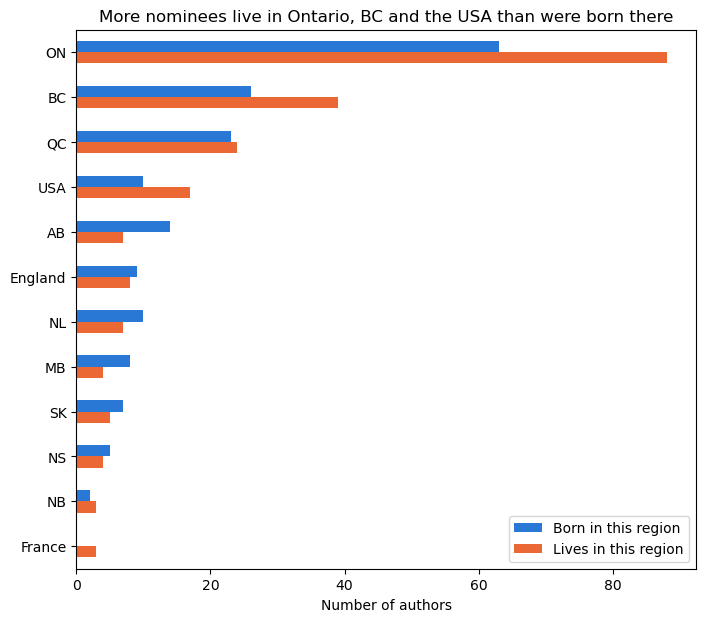

In [65]:
ax = top_regions[["Born in this region", "Lives in this region"]].plot.barh(
    color=["#2a78d6", "#eb6834"],   # blue for born, orange for lives
    figsize=(8, 7),
)

ax.invert_yaxis()   # barh draws the first row at the bottom; this puts the biggest region on top
ax.set_title("More nominees live in Ontario, BC and the USA than were born there")
ax.set_xlabel("Number of authors")
ax.set_ylabel("")
plt.show()

Compare each pair of bars. Where is the orange bar longer than the blue one? Those are the regions nominees move *to*.

### Chart 2: How Canadian are the nominees?

Our crosstab from section 4 can be plotted directly. With `stacked=True`, each bar is one row of the table (born in Canada, born elsewhere), split into its columns (lives in Canada, lives elsewhere).

The crosstab's labels are `True` and `False`, which won't mean much to a reader, so we rename them first. Renaming works with a dictionary, just like `.replace()`: old label → new label. Then `.loc[rows, columns]` picks the rows and columns we want, in the order we list them.

In [66]:
groups = pd.crosstab(known["Born in Canada"], known["Lives in Canada"])

groups = groups.rename(
    index={True: "Born in Canada", False: "Born elsewhere"},
    columns={True: "Lives in Canada", False: "Lives elsewhere"},
)
groups = groups.loc[["Born in Canada", "Born elsewhere"],      # put the rows in this order
                    ["Lives in Canada", "Lives elsewhere"]]    # and the columns in this order

groups

Lives in Canada,Lives in Canada,Lives elsewhere
Born in Canada,,
Born in Canada,134,25
Born elsewhere,46,9


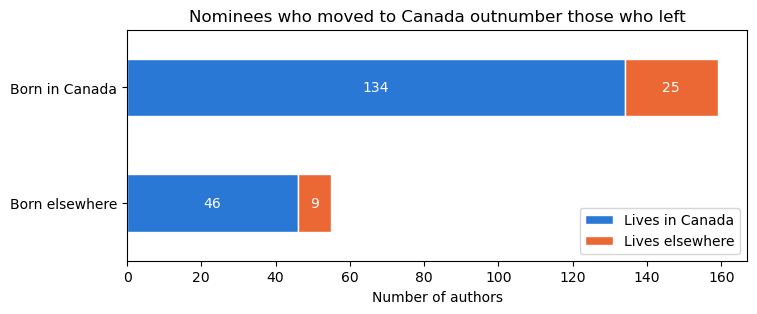

In [67]:
ax = groups.plot.barh(
    stacked=True,
    color=["#2a78d6", "#eb6834"],
    edgecolor="white",   # a thin white gap between the two parts of each bar
    figsize=(8, 3),
)

ax.invert_yaxis()

# Write the number of authors in the middle of each part of each bar
for part in ax.containers:
    ax.bar_label(part, label_type="center", color="white")

ax.set_title("Nominees who moved to Canada outnumber those who left")
ax.set_xlabel("Number of authors")
ax.set_ylabel("")
ax.legend(title="")   # the legend's labels already say what they mean
plt.show()

### Chart 3: Are the nominees concentrated in the big cities?

This chart has one job: to show that one number is much higher than the others. So we colour that bar blue and the other one gray, and we draw the census figure as a **reference line** rather than another bar. Remember from section 5 that a percentage only means something when we compare it with something else. The line makes that comparison visible.

Two more matplotlib tools appear here: `ax.axvline()` draws a vertical line at a given value, and `ax.text()` writes a label at a given position. (`"\n"` inside a string starts a new line, so the long labels and the title wrap. `ax.bar_label()` writes each bar's value on the bar, and `fmt="%.0f%%"` formats it like `:.0f` in an f-string, followed by a `%` sign.)

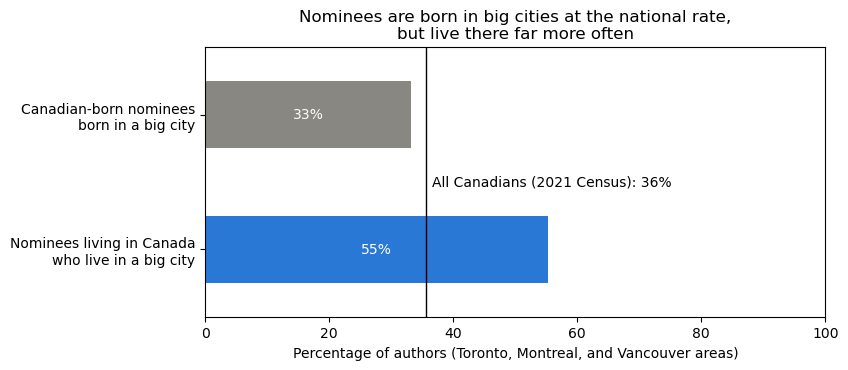

In [68]:
big_city = pd.Series({
    "Canadian-born nominees\nborn in a big city": born_big,
    "Nominees living in Canada\nwho live in a big city": lives_big,
})

ax = big_city.plot.barh(color=["#898781", "#2a78d6"], figsize=(8, 3.5))

ax.invert_yaxis()
ax.set_xlim(0, 100)

# A reference line for all Canadians, labelled in the space between the bars
ax.axvline(census_big, color="black", linewidth=1)
ax.text(census_big + 1, 0.5, f"All Canadians (2021 Census): {census_big:.0f}%", va="center")

# Write each bar's percentage in the middle of the bar
ax.bar_label(ax.containers[0], fmt="%.0f%%", label_type="center", color="white")

ax.set_title("Nominees are born in big cities at the national rate,\nbut live there far more often")
ax.set_xlabel("Percentage of authors (Toronto, Montreal, and Vancouver areas)")
ax.set_ylabel("")
plt.show()

### Chart 4: A map of nominees by province

A map is a natural way to show geography, but we need two things a bar chart doesn't:

1. **The shapes of the provinces.** The file `canada_provinces.geojson` (in this folder) stores the outline of each province and territory, along with its name and the same two-letter abbreviations we use in our `region` columns.

   *Source:* Statistics Canada, 2016 Census Boundary Files: Provinces/territories, cartographic boundary file (`lpr_000b16g_e.gml`; see *Boundary Files, Reference Guide*, Catalogue no. 92-160-G), used under the [Statistics Canada Open Licence](https://www.statcan.gc.ca/en/reference/licence). For this course we simplified the outlines and removed islands smaller than 20 km² to make the file smaller, converted it to GeoJSON, and added the `region` column of two-letter abbreviations. Provincial and territorial boundaries did not change between the 2016 and 2021 censuses.
2. **A library that can draw shapes.** **geopandas** is pandas with an extra column, `geometry`, that holds a shape for each row. Everything else works like the DataFrames we already know.

In [69]:
import geopandas as gpd

provinces = gpd.read_file("canada_provinces.geojson")

# Latitude and longitude stretch Canada's north. This "projection" is the one
# Statistics Canada uses for its own maps.
provinces = provinces.to_crs(3347)

provinces[["name", "region"]]

,name,region
0,Alberta,AB
1,British Columbia,BC
2,Manitoba,MB
3,New Brunswick,NB
4,Newfoundland and Labrador,NL
5,Northwest Territories,NT
6,Nova Scotia,NS
7,Nunavut,NU
8,Ontario,ON
9,Prince Edward Island,PE


### Compared to what? Nominees per million people

If we coloured each province by its *number* of nominees, the map would mostly show us where Canadians live. Ontario would be darkest simply because it has the most people. Instead we divide by population to get **nominees per million people**, which asks whether a province produces more nominees than its size would suggest.

`.map()` looks up each value of a column in a dictionary (or Series) and gives back what it finds. Here it adds each province's population and its two counts as new columns. A province that isn't found gets `NaN`.

In [70]:
# Statistics Canada, 2021 Census.
# The three territories are left out on purpose: with fewer than 50,000 people
# each, a single author would make their rate look enormous (one nominee in
# Nunavut works out to 27 per million). Leaving them out makes their rate NaN.
population = {
    "AB": 4262635,
    "BC": 5000879,
    "MB": 1342153,
    "NB": 775610,
    "NL": 510550,
    "NS": 969383,
    "ON": 14223942,
    "PE": 154331,
    "QC": 8501833,
    "SK": 1132505,
}

provinces["population"] = provinces["region"].map(population)
provinces["born"] = provinces["region"].map(known_born["Born region"].value_counts()).fillna(0)
provinces["lives"] = provinces["region"].map(home_region.value_counts()).fillna(0)

provinces["born per million"] = provinces["born"] / provinces["population"] * 1000000
provinces["lives per million"] = provinces["lives"] / provinces["population"] * 1000000

provinces[["name", "born", "lives", "born per million", "lives per million"]].round(1)

,name,born,lives,born per million,lives per million
0,Alberta,14.0,7.0,3.3,1.6
1,British Columbia,26.0,39.0,5.2,7.8
2,Manitoba,8.0,4.0,6.0,3.0
3,New Brunswick,2.0,3.0,2.6,3.9
4,Newfoundland and Labrador,10.0,7.0,19.6,13.7
5,Northwest Territories,0.0,0.0,NaN,NaN
6,Nova Scotia,5.0,4.0,5.2,4.1
7,Nunavut,1.0,1.0,NaN,NaN
8,Ontario,63.0,88.0,4.4,6.2
9,Prince Edward Island,0.0,0.0,0.0,0.0


Now we draw two maps side by side, one for birthplaces and one for residences. `plt.subplots(1, 2)` makes a figure with 1 row and 2 charts, and gives back both `ax`es in a list called `axes`. (`layout="constrained"` asks matplotlib to fit the titles and colour bars in neatly.)

Two details make the maps honest to compare:
- **Both maps use the same colour scale** (`vmin` and `vmax`), so the same shade means the same rate on each map.
- **One colour, light to dark** (`cmap="Blues"`): darker always means more. We use blue for both maps here, because a reader should compare the two maps' shades directly.

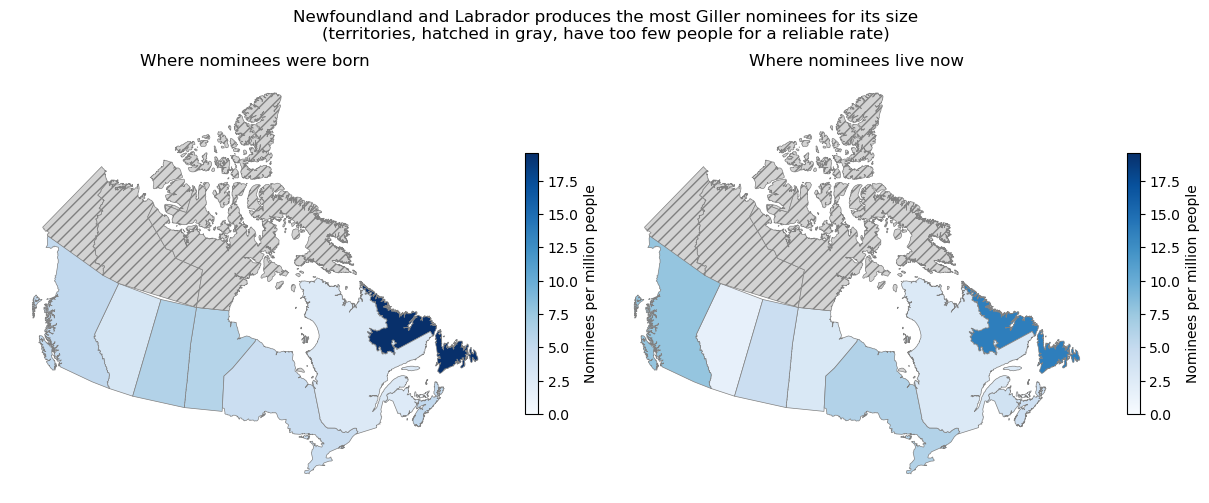

In [71]:
# The same scale for both maps: from 0 to the highest rate on either map
highest = max(provinces["born per million"].max(), provinces["lives per million"].max())

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")

for ax, column, title in [(axes[0], "born per million", "Where nominees were born"),
                          (axes[1], "lives per million", "Where nominees live now")]:
    provinces.plot(
        column=column,
        ax=ax,
        cmap="Blues",
        vmin=0,
        vmax=highest,
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"label": "Nominees per million people", "shrink": 0.6},
        missing_kwds={"color": "lightgray", "hatch": "///", "edgecolor": "gray"},
    )
    ax.set_title(title)
    ax.set_axis_off()   # latitude and longitude ticks don't help a reader here

fig.suptitle("Newfoundland and Labrador produces the most Giller nominees for its size\n"
             "(territories, hatched in gray, have too few people for a reliable rate)")
plt.show()

Some things to notice:
- Ontario has by far the most nominees, but for its population it is only in the middle of the pack as a *birthplace*. As a place to *live*, it rises to third, behind Newfoundland and Labrador and British Columbia.
- British Columbia gets darker from the first map to the second, and Alberta gets lighter. Which provinces do nominees leave, and which do they move to?
- Our map leaves out every nominee born or living outside Canada, and the author whose birthplace is recorded only as `Canada`. The `Treaty 6 Territory` doesn't match a province either, so it isn't counted. A map always shows *some* of the data. What it leaves out is a decision, just like our cleaning decisions.
- We divided by the *2021* population, but many nominees were born decades earlier, when the provinces' shares of Canada's population were different.

**Discussion:**
- Which chart makes its point most clearly? Which one would you put in an essay about the Giller Prize, and why?
- Chart 1 leaves out every region outside the top 12. Which authors does that hide? Does it matter for the story the chart tells?
- Chart 3 compares a gray bar, a blue bar, and a black line. What would change if all three were bars of the same colour?
- Chart 4 shows rates per million people. What story would a map of raw counts tell instead? Which is the fairer picture of Canadian literary geography?

## 7. Plain Python or pandas?

We got the same answers both ways, because we made the same decisions: one row per author, the "first place listed" rule, the same `corrections` and `metro_areas` dictionaries, and the same list of big cities. Pandas didn't make any of those decisions for us.

What pandas changes is how much code we write. Operations like `.value_counts()`, `.isin()`, and `pd.crosstab()` replace loops we wrote by hand. That makes pandas faster to write once you know it, but it also hides the steps. When a result looks surprising, it can be harder to see *why*.

**Discussion:** Compare the four-group calculation here (section 4) with the one in the notes. Which one would you rather explain to a reader who doesn't program? Which one would you rather use for a data set with 100,000 rows?